# Optimisation différentiable : méthode du gradient à pas fixe et méthode du gradient conjugué

**Niveau :** 4ᵉ année — Sciences des Données et Intelligence Artificielle  
**Outils :** NumPy, SymPy, Pandas, Matplotlib

---

## Plan du notebook

1. Introduction
2. Énoncé de l'exercice
3. Résolution mathématique
4. Implémentation Python
5. Résultats et visualisations
6. Interprétation et conclusion

## Partie 1 — Introduction

### 1.1 L'optimisation différentiable

On cherche le minimum d'une fonction dérivable $f : \mathbb{R}^n \to \mathbb{R}$ :

$$\min_{x \in \mathbb{R}^n} f(x).$$

Les algorithmes de **descente** construisent une suite $x_{k+1} = x_k + \alpha_k d_k$, où $d_k$ est une **direction de descente** ($\nabla f(x_k)^\top d_k < 0$) et $\alpha_k > 0$ un **pas**.

Les méthodes de Newton et BFGS (notebooks précédents) utilisent ou reconstruisent l'information de **courbure** (le Hessien). Les deux méthodes étudiées ici sont des méthodes **du premier ordre** : elles n'utilisent que le **gradient**. Chaque itération ne coûte donc qu'un gradient et quelques opérations vectorielles ($O(n)$), sans Hessien ni système linéaire.

### 1.2 Méthode du gradient à pas fixe

La direction est l'opposée du gradient (direction de plus forte descente locale) et le pas est une **constante** $\alpha$ choisie une fois pour toutes :

$$\boxed{\,x_{k+1} = x_k - \alpha\, \nabla f(x_k)\,}$$

**Lemme de descente.** Si $\nabla f$ est $L$-lipschitzienne, alors
$$f(x_{k+1}) \le f(x_k) - \alpha\Bigl(1 - \tfrac{\alpha L}{2}\Bigr)\|\nabla f(x_k)\|^2 ,$$
donc $f$ décroît strictement dès que $0 < \alpha < 2/L$.

**Vitesse locale.** Près d'un minimum $x^\*$ où $H_f(x^\*)$ est définie positive, de valeurs propres $\mu = \lambda_{\min} \le \dots \le \lambda_{\max} = L$, l'erreur $e_k = x_k - x^\*$ vérifie $e_{k+1} \approx (I - \alpha H_f(x^\*))\, e_k$. La suite converge donc **linéairement** avec le taux
$$\rho(\alpha) = \max_i |1 - \alpha \lambda_i|,$$
qui est $<1$ si et seulement si $0 < \alpha < 2/L$. Le meilleur pas est $\alpha_{\rm opt} = \dfrac{2}{\mu + L}$, pour lequel
$$\rho_{\rm opt} = \frac{L-\mu}{L+\mu} = \frac{\kappa - 1}{\kappa + 1}, \qquad \kappa = \frac{L}{\mu} \ \text{(conditionnement)}.$$

### 1.3 Méthode du gradient conjugué

**Cas quadratique.** Pour $q(x) = \tfrac12 x^\top A x - b^\top x$ avec $A$ symétrique définie positive, deux directions $d_i, d_j$ sont dites **$A$-conjuguées** si $d_i^\top A d_j = 0$ pour $i \ne j$. Minimiser successivement $q$ le long de $n$ directions $A$-conjuguées donne le minimum **exact en au plus $n$ itérations**. Le gradient conjugué construit ces directions « à la volée », à partir des seuls gradients :

$$d_0 = -g_0, \qquad \alpha_k = \frac{\|g_k\|^2}{d_k^\top A d_k}, \qquad x_{k+1} = x_k + \alpha_k d_k, \qquad \beta_k = \frac{\|g_{k+1}\|^2}{\|g_k\|^2}, \qquad d_{k+1} = -g_{k+1} + \beta_k d_k .$$

Le pas $\alpha_k$ est le **pas optimal** (minimiseur exact de $q$ le long de $d_k$). La direction $d_{k+1}$ « corrige » le gradient avec la direction précédente, ce qui évite le zigzag de la descente de gradient.

**Cas non quadratique.** On garde la même structure, avec :

- un pas $\alpha_k = \arg\min_{\alpha>0} f(x_k + \alpha d_k)$ (recherche linéaire exacte) ou vérifiant les conditions de Wolfe ;
- plusieurs choix pour le coefficient $\beta_k$ :

| Variante | $\beta_k$ |
|---|---|
| Fletcher–Reeves (FR) | $\dfrac{\|g_{k+1}\|^2}{\|g_k\|^2}$ |
| Polak–Ribière (PR) | $\dfrac{g_{k+1}^\top (g_{k+1} - g_k)}{\|g_k\|^2}$ ; on utilise en pratique $\beta_k^{PR+} = \max(0, \beta_k^{PR})$ |

- éventuellement un **redémarrage** ($\beta_k = 0$, donc $d_{k+1} = -g_{k+1}$) toutes les $n$ itérations.

Dans la suite, « méthode du gradient à pas conjugué » désigne cette méthode du **gradient conjugué**.

## Partie 2 — Énoncé de l'exercice

On considère la même fonction de deux variables que pour les méthodes de Newton et BFGS :

$$f(x,y) = x^4 + y^4 - 4xy.$$

**Questions :**

1. Calculer le gradient et la matrice Hessienne de $f$, puis déterminer et classifier ses points critiques.
2. **Gradient à pas fixe.** Établir la condition de décroissance sur le pas $\alpha$ (valeur de $L$), puis le pas optimal et le taux de convergence locaux à partir des valeurs propres du Hessien au minimum.
3. Appliquer le gradient à pas fixe à partir de $x_0 = (2;\ 1{,}5)$ avec le critère d'arrêt $\|\nabla f(x_k)\|_2 < 10^{-10}$, en justifiant le choix de $\alpha$, puis étudier l'influence de $\alpha$.
4. **Gradient conjugué.** (a) Vérifier sur le modèle quadratique local que la méthode converge en $n = 2$ itérations. (b) Établir le pas optimal pour $f$ (non quadratique). (c) Appliquer les variantes FR et PR+ à partir de $x_0$, avec le même critère d'arrêt.
5. Présenter les tableaux d'itérations, les courbes de convergence et les chemins suivis sur les courbes de niveau.
6. Comparer ces deux méthodes avec Newton et BFGS.
7. Discuter les limites : choix du pas, point initial et point selle, conditionnement, perte de conjugaison et redémarrage.

## Partie 3 — Résolution mathématique

### 3.1 Fonction objectif, gradient, Hessien et points critiques

$$f(x,y) = x^4 + y^4 - 4xy, \qquad \nabla f(x,y) = \begin{pmatrix} 4x^3 - 4y \\ 4y^3 - 4x \end{pmatrix}, \qquad H_f(x,y) = \begin{pmatrix} 12x^2 & -4 \\ -4 & 12y^2 \end{pmatrix}.$$

La condition $\nabla f = 0$ donne $y = x^3$ et $x = y^3$, d'où $x = x^9$, soit $x \in \{0, 1, -1\}$ :

| Point | $\det H_f$ | Valeurs propres de $H_f$ | Nature | $f$ |
|---|---|---|---|---|
| $(0,0)$ | $-16$ | $\pm 4$ | point selle | $0$ |
| $(1,1)$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |
| $(-1,-1)$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |

Comme $f \to +\infty$ à l'infini, $-2$ est le minimum global, atteint en $(1,1)$ et $(-1,-1)$. Ici encore, le Hessien ne sert qu'à **vérifier** les résultats et à **analyser** la convergence ; les deux algorithmes étudiés ne l'utilisent pas.

### 3.2 Gradient à pas fixe : choix du pas

**Constante $L$.** Les valeurs propres du Hessien sont
$$\lambda_\pm(x,y) = 6(x^2+y^2) \pm \sqrt{36\,(x^2-y^2)^2 + 16}.$$
Elles croissent avec $\|(x,y)\|$ : la courbure est très grande loin de l'origine. En $x_0 = (2;1{,}5)$, $H_f(x_0) = \begin{pmatrix}48&-4\\-4&27\end{pmatrix}$ a pour valeurs propres $\approx 26{,}26$ et $48{,}74$, donc $2/\lambda_{\max} \approx 0{,}041$. Sur l'ensemble de sous-niveau $\{f \le f(x_0)\}$, que les itérés ne quittent pas si $f$ décroît, on calcule numériquement (§5.1) $L \approx 49{,}5$, soit $\alpha < 2/L \approx 0{,}0404$.

**Condition locale.** En $(1,1)$ (et $(-1,-1)$), $\mu = 8$ et $L_{\rm loc} = 16$ :

- convergence locale si et seulement si $\alpha < 2/16 = 0{,}125$ ;
- pas optimal $\alpha_{\rm opt} = \dfrac{2}{8+16} = \dfrac{1}{12} \approx 0{,}0833$, de taux $\rho_{\rm opt} = \dfrac{16-8}{16+8} = \dfrac13$ ($\kappa = 2$ : problème très bien conditionné).

**Dilemme du pas fixe.** Le pas doit être assez petit pour la **pire** courbure rencontrée (loin du minimum : $\alpha \lesssim 0{,}04$), alors qu'il serait bien plus efficace près du minimum ($\alpha = 1/12$). On choisit donc pour l'exécution principale

$$\alpha = 0{,}04 \;(< 2/L \approx 0{,}0404), \qquad \rho(0{,}04) = \max\bigl(|1-0{,}32|,\ |1-0{,}64|\bigr) = 0{,}68 .$$

Le nombre d'itérations attendu est de l'ordre de $\ln(\varepsilon/\|g_0\|)/\ln\rho \approx 68$.

### 3.3 Gradient conjugué : formules

**Pas optimal (cas quadratique).** $\dfrac{d}{d\alpha}\, q(x_k + \alpha d_k) = g_k^\top d_k + \alpha\, d_k^\top A d_k = 0$, d'où $\alpha_k = -\dfrac{g_k^\top d_k}{d_k^\top A d_k}$. Comme $g_k^\top d_k = -\|g_k\|^2$, on retrouve $\alpha_k = \dfrac{\|g_k\|^2}{d_k^\top A d_k}$.

**Coefficient $\beta_k$.** On impose $d_{k+1}^\top A d_k = 0$ (conjugaison) avec $d_{k+1} = -g_{k+1} + \beta_k d_k$, d'où $\beta_k = \dfrac{g_{k+1}^\top A d_k}{d_k^\top A d_k}$. En utilisant $A d_k = (g_{k+1}-g_k)/\alpha_k$ puis l'orthogonalité des gradients successifs, on obtient les formules FR et PR, qui coïncident dans le cas quadratique avec recherche linéaire exacte. Elles diffèrent dès que $f$ n'est pas quadratique.

**Pas optimal pour $f(x,y) = x^4 + y^4 - 4xy$.** Pour $p = (x,y)$ et $d = (u,v)$, la fonction $\varphi(\alpha) = f(p + \alpha d)$ est un polynôme de **degré 4** en $\alpha$ ; sa dérivée est donc un polynôme de **degré 3** :

$$\varphi'(\alpha) = 4(u^4+v^4)\,\alpha^3 + 12(u^3x+v^3y)\,\alpha^2 + \bigl[12(u^2x^2+v^2y^2) - 8uv\bigr]\alpha + 4(ux^3+vy^3) - 4(uy+vx).$$

(le terme constant vaut $\nabla f(p)^\top d$). Comme $\varphi'(0) = g^\top d < 0$ et $\varphi(\alpha)\to+\infty$, il existe au moins une racine positive. On retient la racine positive qui minimise $\varphi$ : la recherche linéaire est **exacte et sans évaluation supplémentaire du gradient**. Elle assure $\nabla f(x_{k+1})^\top d_k = 0$, donc, pour FR et PR, $\nabla f(x_{k+1})^\top d_{k+1} = -\|g_{k+1}\|^2 < 0$ : $d_{k+1}$ est **toujours** une direction de descente.

### 3.4 Algorithmes

**Gradient à pas fixe.**

1. Choisir $x_0$, $\alpha$, $\varepsilon = 10^{-10}$.
2. Pour $k = 0, 1, \dots$ : calculer $g_k = \nabla f(x_k)$ ; si $\|g_k\|_2 < \varepsilon$, arrêter ; sinon $x_{k+1} = x_k - \alpha g_k$.

**Gradient conjugué (FR / PR+).**

1. Choisir $x_0$, $\varepsilon = 10^{-10}$ ; $g_0 = \nabla f(x_0)$ ; $d_0 = -g_0$.
2. Pour $k = 0, 1, \dots$ :
   1. si $\|g_k\|_2 < \varepsilon$, arrêter ;
   2. $\alpha_k$ = racine positive de $\varphi_k'$ minimisant $\varphi_k(\alpha) = f(x_k + \alpha d_k)$ ;
   3. $x_{k+1} = x_k + \alpha_k d_k$, $g_{k+1} = \nabla f(x_{k+1})$ ;
   4. $\beta_k$ (FR ou PR+), puis $d_{k+1} = -g_{k+1} + \beta_k d_k$.

**Point initial.** On garde $x_0 = (2;\ 1{,}5)$ : $f(x_0) = 9{,}0625$, $\nabla f(x_0) = (26;\ 5{,}5)$ et $\|\nabla f(x_0)\|_2 \approx 26{,}58$.

## Partie 4 — Implémentation Python

### 4.1 Imports et réglages

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:.10g}")
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 4.2 Calcul symbolique (SymPy) et fonctions numériques

Le Hessien exact sert uniquement à **vérifier** les résultats et à **analyser** la convergence ; les algorithmes n'en ont pas besoin.

In [2]:
x, y = sp.symbols("x y", real=True)
f_sym    = x**4 + y**4 - 4*x*y
grad_sym = sp.Matrix([sp.diff(f_sym, x), sp.diff(f_sym, y)])
hess_sym = sp.hessian(f_sym, (x, y))

print("f(x,y) =", f_sym)
sp.pprint(grad_sym)
sp.pprint(hess_sym)

f_num    = sp.lambdify((x, y), f_sym, "numpy")
grad_num = sp.lambdify((x, y), grad_sym, "numpy")
hess_num = sp.lambdify((x, y), hess_sym, "numpy")

def f(p):    return float(f_num(p[0], p[1]))
def grad(p): return np.array(grad_num(p[0], p[1]), dtype=float).ravel()
def hess(p): return np.array(hess_num(p[0], p[1]), dtype=float)   # utilisé uniquement pour vérifier/analyser

p0 = np.array([2.0, 1.5])
print("\nf(p0)    =", f(p0))
print("grad(p0) =", grad(p0), "  ||grad(p0)|| =", np.linalg.norm(grad(p0)))

f(x,y) = x**4 - 4*x*y + y**4
⎡   3       ⎤
⎢4⋅x  - 4⋅y ⎥
⎢           ⎥
⎢          3⎥
⎣-4⋅x + 4⋅y ⎦
⎡    2       ⎤
⎢12⋅x    -4  ⎥
⎢            ⎥
⎢           2⎥
⎣ -4    12⋅y ⎦

f(p0)    = 9.0625
grad(p0) = [26.   5.5]   ||grad(p0)|| = 26.575364531836623


### 4.3 Vérification des points critiques et de leur nature

In [3]:
sols = sp.solve(list(grad_sym), (x, y), dict=True)
rows = []
for s in sols:
    H = hess_sym.subs(s)
    eigs = list(H.eigenvals().keys())
    nature = ("minimum local strict" if all(e > 0 for e in eigs)
              else "maximum local strict" if all(e < 0 for e in eigs) else "point selle")
    rows.append({"point": (s[x], s[y]), "f": f_sym.subs(s), "det(H)": H.det(),
                 "valeurs propres": eigs, "nature": nature})
pd.DataFrame(rows)

,point,f,det(H),valeurs propres,nature
0,"(-1, -1)",-2,128,"[16, 8]",minimum local strict
1,"(0, 0)",0,-16,"[-4, 4]",point selle
2,"(1, 1)",-2,128,"[16, 8]",minimum local strict


### 4.4 Étape 1 — Gradient à pas fixe

La fonction renvoie l'historique des itérations. Un garde-fou arrête l'algorithme si la norme du gradient dépasse $10^8$ (divergence), et la fonction `statut` résume l'issue de l'exécution.

In [4]:
def gradient_pas_fixe(p0, alpha, tol=1e-10, max_iter=20000, seuil_div=1e8):
    # Gradient à pas fixe : x_{k+1} = x_k - alpha * grad f(x_k). Retourne l'historique (DataFrame).
    p = np.array(p0, dtype=float)
    historique = []
    for k in range(max_iter + 1):
        g = grad(p)                                     # 1. gradient
        norme_g = np.linalg.norm(g)
        historique.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": norme_g})
        if norme_g < tol or k == max_iter:              # 3. critère de convergence
            break
        if not np.isfinite(norme_g) or norme_g > seuil_div:   # garde-fou : divergence
            break
        p = p - alpha * g                               # 2. mise à jour à pas fixe
    return pd.DataFrame(historique)

def statut(r, tol=1e-10):
    gfin = r["||grad||"].values[-1]
    if gfin < tol:                          return "converge"
    if (not np.isfinite(gfin)) or gfin > 1e8: return "diverge"
    return "non convergé"

### 4.5 Étape 2 — Gradient conjugué sur le modèle quadratique

On code d'abord la version **linéaire** de la méthode (pas optimal et $\beta_k$ de Fletcher–Reeves, formules du §1.3), pour vérifier sa propriété de **terminaison finie** : au plus $n$ itérations pour une quadratique. Le modèle utilisé est $q(z) = \tfrac12 z^\top A z$ avec $A = H_f(1,1)$, où $z = (x,y) - (1,1)$.

In [5]:
def gc_quadratique(A, b, z0, tol=1e-12, max_iter=10):
    # Gradient conjugué linéaire pour q(z) = 1/2 z^T A z - b^T z (A symétrique définie positive).
    z = np.array(z0, dtype=float)
    g = A @ z - b
    d = -g
    conj = np.nan
    lignes = []
    for k in range(max_iter + 1):
        ng = np.linalg.norm(g)
        lignes.append({"k": k, "z1": z[0], "z2": z[1], "||g||": ng, "d_{k-1}^T A d_k": conj})
        if ng < tol:
            break
        alpha = (g @ g) / (d @ A @ d)            # pas optimal
        z = z + alpha * d
        g_new = A @ z - b
        beta = (g_new @ g_new) / (g @ g)         # Fletcher-Reeves
        d_new = -g_new + beta * d
        conj = d @ A @ d_new                     # doit valoir 0 (conjugaison)
        g, d = g_new, d_new
    return pd.DataFrame(lignes)

A_loc = hess(np.array([1.0, 1.0]))               # [[12, -4], [-4, 12]]
z0 = p0 - np.array([1.0, 1.0])                   # le point x0 = (2 ; 1,5) exprimé dans le modèle local
gc_quadratique(A_loc, np.zeros(2), z0)

,k,z1,z2,||g||,d_{k-1}^T A d_k
0,0,1,0.5,10.19803903,NaN
1,1,0.04411764706,0.3088235294,3.599307892,6.394884622e-14
2,2,1.387778781e-17,0,1.755416734e-16,-3.835455598e-15


### 4.6 Étape 3 — Pas optimal pour $f$ (recherche linéaire exacte)

On vérifie d'abord avec SymPy que les coefficients du polynôme cubique $\varphi'(\alpha)$ établis au §3.3 sont exacts.

In [6]:
a, u, v = sp.symbols("a u v", real=True)
phi  = f_sym.subs({x: x + a*u, y: y + a*v}, simultaneous=True)       # phi(a) = f(p + a d)
dphi = sp.expand(sp.diff(phi, a))
c3, c2, c1, c0 = sp.Poly(dphi, a).all_coeffs()
formules = [4*(u**4 + v**4),
            12*(u**3*x + v**3*y),
            12*(u**2*x**2 + v**2*y**2) - 8*u*v,
            4*(u*x**3 + v*y**3) - 4*(u*y + v*x)]
print("écarts entre coefficients SymPy et formules :", [sp.simplify(c - fo) for c, fo in zip([c3, c2, c1, c0], formules)])

écarts entre coefficients SymPy et formules : [0, 0, 0, 0]


In [7]:
def pas_optimal(p, d):
    # Pas exact : racine positive de phi'(a) = d^T grad f(p + a d) (cubique) qui minimise phi(a) = f(p + a d).
    x_, y_ = p
    u_, v_ = d
    coeffs = [4*(u_**4 + v_**4),
              12*(u_**3*x_ + v_**3*y_),
              12*(u_**2*x_**2 + v_**2*y_**2) - 8*u_*v_,
              4*(u_*x_**3 + v_*y_**3) - 4*(u_*y_ + v_*x_)]
    racines = np.roots(coeffs)
    racines = racines[np.abs(racines.imag) < 1e-9].real
    racines = racines[racines > 0]
    dcoeffs = np.polyder(coeffs)
    for _ in range(2):                                   # raffinement de Newton (précision machine)
        racines = racines - np.polyval(coeffs, racines) / np.polyval(dcoeffs, racines)
    return racines[np.argmin([f(p + r*d) for r in racines])]

# Test au point initial, direction d = -grad f
g0 = grad(p0); d0 = -g0
alpha0 = pas_optimal(p0, d0)
grille = np.linspace(0, 0.2, 200001)
phi_grille = np.array([f(p0 + t*d0) for t in grille[::100]])
print(f"alpha optimal (cubique)            = {alpha0:.10f}")
print(f"alpha optimal (balayage numérique) = {grille[::100][np.argmin(phi_grille)]:.4f}")
print(f"grad f(x0 + alpha d0)^T d0         = {grad(p0 + alpha0*d0) @ d0:.2e}   (attendu : 0)")

alpha optimal (cubique)            = 0.0378204570
alpha optimal (balayage numérique) = 0.0378
grad f(x0 + alpha d0)^T d0         = 1.15e-14   (attendu : 0)


### 4.7 Étape 4 — Gradient conjugué non linéaire (FR, PR+)

Chaque itération suit les étapes : **gradient → pas optimal → mise à jour de $x$ → $\beta_k$ → nouvelle direction → test de convergence**. L'argument `redemarrage` permet de remplacer $\beta_k$ par $0$ toutes les $m$ itérations.

In [8]:
def gradient_conjugue(p0, variante="FR", tol=1e-10, max_iter=500, redemarrage=None):
    # Gradient conjugué non linéaire (variantes "FR" et "PR+") avec recherche linéaire exacte.
    p = np.array(p0, dtype=float)
    g = grad(p)
    d = -g
    historique = []
    for k in range(max_iter + 1):
        norme_g = np.linalg.norm(g)
        historique.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": norme_g,
                           "alpha": np.nan, "beta": np.nan, "g_{k+1}^T d_k": np.nan})
        if norme_g < tol or k == max_iter:                 # critère de convergence
            break
        if g @ d >= 0:                                     # sécurité : d doit être une direction de descente
            d = -g
        alpha = pas_optimal(p, d)                          # 1. pas optimal
        p_new = p + alpha * d                              # 2. mise à jour des variables
        g_new = grad(p_new)
        if variante == "FR":                               # 3. coefficient beta
            beta = (g_new @ g_new) / (g @ g)
        elif variante == "PR+":
            beta = max(0.0, g_new @ (g_new - g) / (g @ g))
        else:
            raise ValueError("variante inconnue")
        if redemarrage and (k + 1) % redemarrage == 0:     # redémarrage périodique éventuel
            beta = 0.0
        historique[-1].update({"alpha": alpha, "beta": beta, "g_{k+1}^T d_k": g_new @ d})
        d = -g_new + beta * d                              # 4. nouvelle direction
        p, g = p_new, g_new
    return pd.DataFrame(historique)

## Partie 5 — Résultats et visualisations

### 5.1 Gradient à pas fixe : choix du pas

On calcule la constante $L$ (plus grande valeur propre du Hessien) sur l'ensemble de sous-niveau $\{f \le f(x_0)\}$ et on compare avec le pas théorique $2/L$.

In [9]:
xs_ = np.linspace(-3, 3, 1201)
X_, Y_ = np.meshgrid(xs_, xs_)
Z_ = f_num(X_, Y_)
lam_max = 6*(X_**2 + Y_**2) + np.sqrt(36*(X_**2 - Y_**2)**2 + 16)      # plus grande valeur propre de H_f
L_sous = lam_max[Z_ <= f(p0)].max()

print("Valeurs propres de H_f(x0)        :", np.linalg.eigvalsh(hess(p0)))
print(f"L sur {{f <= f(x0)}}                 : {L_sous:.3f}   ->  2/L = {2/L_sous:.4f}")
print("Valeurs propres de H_f(1,1)       :", np.linalg.eigvalsh(hess(np.array([1., 1.]))))
mu_loc, L_loc = 8.0, 16.0
print(f"Seuil local 2/L_loc = {2/L_loc},  pas optimal local 2/(mu+L) = {2/(mu_loc+L_loc):.4f},  taux optimal = {(L_loc-mu_loc)/(L_loc+mu_loc):.4f}")

alpha_fixe = 0.04
print(f"\nPas retenu : alpha = {alpha_fixe}  (< 2/L = {2/L_sous:.4f}),  taux local théorique rho = {max(abs(1-alpha_fixe*mu_loc), abs(1-alpha_fixe*L_loc)):.2f}")

Valeurs propres de H_f(x0)        : [26.26389747 48.73610253]
L sur {f <= f(x0)}                 : 49.540   ->  2/L = 0.0404
Valeurs propres de H_f(1,1)       : [ 8. 16.]
Seuil local 2/L_loc = 0.125,  pas optimal local 2/(mu+L) = 0.0833,  taux optimal = 0.3333

Pas retenu : alpha = 0.04  (< 2/L = 0.0404),  taux local théorique rho = 0.68


### 5.2 Tableau des itérations du gradient à pas fixe

Le tableau complet compte une soixantaine de lignes : on affiche les 8 premières et les 5 dernières.

In [10]:
res_gd = gradient_pas_fixe([2.0, 1.5], alpha_fixe, tol=1e-10)
res_gd.iloc[list(range(8)) + list(range(len(res_gd) - 5, len(res_gd)))]

,k,x,y,"f(x,y)",||grad||
0,0,2,1.5,9.0625,26.57536453
1,1,0.96,1.28,-1.38149888,4.815555296
2,2,1.02324224,1.09805568,-1.944271277,1.207579933
3,3,1.027513568,1.049941705,-1.985400918,0.5380887608
4,4,1.021931037,1.029154724,-1.994429491,0.3121455074
5,5,1.015836342,1.018257458,-1.997611375,0.1998338401
6,6,1.011035076,1.011866719,-1.998936155,0.1321359297
7,7,1.007578249,1.007868445,-1.999518766,0.08845733639
57,57,1,1,-2,3.626461393e-10
58,58,1,1,-2,2.465999776e-10


### 5.3 Analyse de l'erreur et vitesse de convergence

Le minimum exact est $x^\* = (1,1)$. On calcule $e_k = \|x_k - x^\*\|_2$ et le rapport $e_{k+1}/e_k$. Pour une convergence **linéaire**, ce rapport tend vers une constante $\rho \in\, ]0,1[$ ; ici on attend $\rho(\alpha) = \max_i |1-\alpha\lambda_i|$ avec $\lambda_i \in \{8, 16\}$.

In [11]:
x_star = np.array([1.0, 1.0])
res_gd["erreur"] = np.linalg.norm(res_gd[["x", "y"]].values - x_star, axis=1)
res_gd["e_{k+1}/e_k"] = np.r_[res_gd["erreur"].values[1:] / res_gd["erreur"].values[:-1], np.nan]

p_gd = res_gd[["x", "y"]].values[-1]
rho_theo = max(abs(1 - alpha_fixe*mu_loc), abs(1 - alpha_fixe*L_loc))
print(f"Itérations effectuées : {len(res_gd)-1}")
print(f"Point final           : ({p_gd[0]:.12f}, {p_gd[1]:.12f})")
print(f"f au point final      : {res_gd['f(x,y)'].values[-1]:.12f}   (valeur théorique : -2)")
print(f"||grad|| final        : {res_gd['||grad||'].values[-1]:.2e}")
print(f"f ne croît jamais (tolérance 1e-14) : {bool(np.all(np.diff(res_gd['f(x,y)'].values) <= 1e-14))}")
print(f"Rapport e_(k+1)/e_k (médiane des 10 dernières valeurs) : {np.nanmedian(res_gd['e_{k+1}/e_k'].values[-11:]):.4f}   (taux théorique rho = {rho_theo:.2f})")
res_gd[["k", "erreur", "e_{k+1}/e_k"]].tail(6)

Itérations effectuées : 61
Point final           : (1.000000000007, 1.000000000007)
f au point final      : -2.000000000000   (valeur théorique : -2)
||grad|| final        : 7.75e-11
f ne croît jamais (tolérance 1e-14) : True
Rapport e_(k+1)/e_k (médiane des 10 dernières valeurs) : 0.6800   (taux théorique rho = 0.68)


,k,erreur,e_{k+1}/e_k
56,56,6.666298561e-11,0.6799990579
57,57,4.533076741e-11,0.6800016625
58,58,3.08249972e-11,0.6800016299
59,59,2.096104834e-11,0.6800047939
60,60,1.425361336e-11,0.6800026437
61,61,9.692494766e-12,NaN


### 5.4 Influence du pas $\alpha$

On relance l'algorithme depuis $x_0$ pour plusieurs valeurs de $\alpha$. Le taux asymptotique **mesuré** est la médiane des 5 derniers rapports $\|g_{k+1}\|/\|g_k\|$ ; il est comparé au taux théorique local $\rho(\alpha) = \max(|1-8\alpha|, |1-16\alpha|)$.

In [12]:
alphas = [0.005, 0.01, 0.02, 0.04, 0.05, 1/12, 0.10, 0.12, 0.125, 0.13, 0.15]
lignes, runs = [], {}
for al in alphas:
    with np.errstate(all="ignore"):
        r = gradient_pas_fixe([2.0, 1.5], al, tol=1e-10, max_iter=20000)
    runs[al] = r
    pf = r[["x", "y"]].values[-1]
    st = statut(r)
    ng = r["||grad||"].values
    taux = float(np.median(ng[-5:] / ng[-6:-1])) if st == "converge" and len(ng) > 6 else np.nan
    lignes.append({"alpha": round(al, 4), "itérations": len(r) - 1, "statut": st,
                   "point final": tuple(np.round(pf, 4)) if np.all(np.abs(pf) < 1e6) else "hors borne",
                   "||grad|| final": f"{ng[-1]:.1e}",
                   "taux mesuré": taux, "taux théorique rho(alpha)": max(abs(1 - 8*al), abs(1 - 16*al))})
pd.DataFrame(lignes)

,alpha,itérations,statut,point final,||grad|| final,taux mesuré,taux théorique rho(alpha)
0,0.005,596,converge,"(1.0, 1.0)",9.8e-11,0.96,0.96
1,0.01,292,converge,"(1.0, 1.0)",9.2e-11,0.9200027609,0.92
2,0.02,139,converge,"(1.0, 1.0)",9.3e-11,0.8399990926,0.84
3,0.04,61,converge,"(1.0, 1.0)",7.8e-11,0.6800016625,0.68
4,0.05,47,converge,"(1.0, 1.0)",9.3e-11,0.6000002102,0.6
5,0.0833,29,converge,"(1.0, 1.0)",3.7e-11,0.3333333327,0.3333333333
6,0.1,40,converge,"(1.0, 1.0)",7.6e-11,0.5999978696,0.6
7,0.12,143,converge,"(-1.0, -1.0)",9.9e-11,0.920000465,0.92
8,0.125,20000,non convergé,"(1.0, 1.0)",1.9e-05,NaN,1
9,0.13,20000,non convergé,"(0.8321, 1.1094)",3.0e+00,NaN,1.08


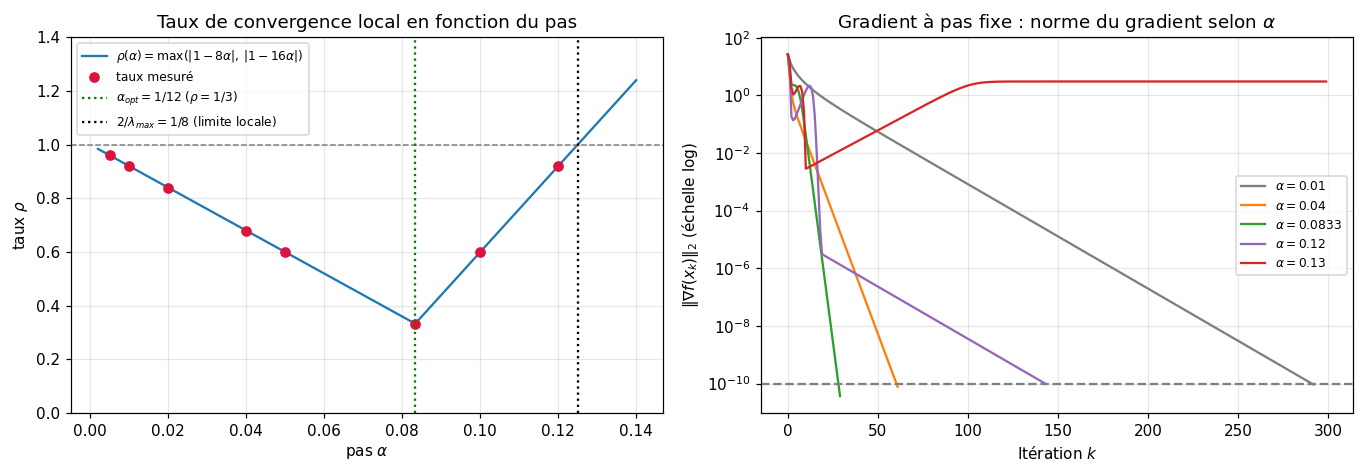

In [13]:
al_ok = np.linspace(0.002, 0.14, 400)
rho_al = np.maximum(np.abs(1 - 8*al_ok), np.abs(1 - 16*al_ok))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax[0].plot(al_ok, rho_al, color="tab:blue", label=r"$\rho(\alpha)=\max(|1-8\alpha|,\,|1-16\alpha|)$")
mesures = [(l["alpha"], l["taux mesuré"]) for l in lignes if not np.isnan(l["taux mesuré"])]
ax[0].plot(*zip(*mesures), "o", color="crimson", label="taux mesuré")
ax[0].axhline(1, color="gray", ls="--", lw=1)
ax[0].axvline(1/12, color="green", ls=":", label=r"$\alpha_{opt}=1/12$ ($\rho=1/3$)")
ax[0].axvline(1/8, color="black", ls=":", label=r"$2/\lambda_{max}=1/8$ (limite locale)")
ax[0].set_ylim(0, 1.4); ax[0].set_xlabel(r"pas $\alpha$"); ax[0].set_ylabel(r"taux $\rho$")
ax[0].set_title("Taux de convergence local en fonction du pas"); ax[0].legend(fontsize=8)

for al, couleur in [(0.01, "tab:gray"), (0.04, "tab:orange"), (1/12, "tab:green"), (0.12, "tab:purple"), (0.13, "tab:red")]:
    r = runs[al].iloc[:300]
    ax[1].semilogy(r["k"], r["||grad||"].clip(lower=1e-16), "-", color=couleur, label=fr"$\alpha={al:.3g}$")
ax[1].axhline(1e-10, color="gray", ls="--")
ax[1].set_title("Gradient à pas fixe : norme du gradient selon $\\alpha$")
ax[1].set_xlabel("Itération $k$"); ax[1].set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.5 Courbes de convergence du gradient à pas fixe ($\alpha = 0{,}04$)

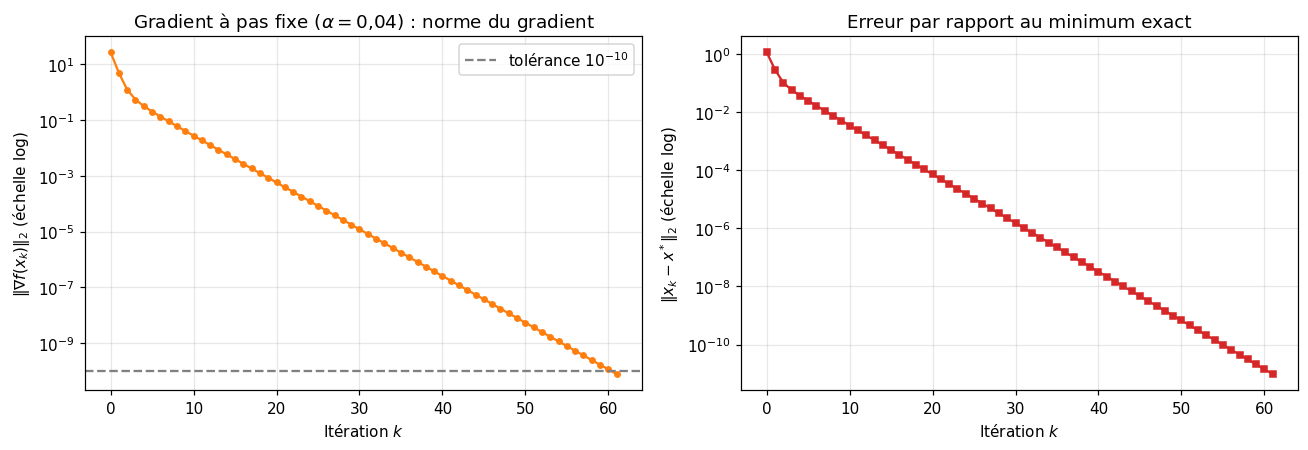

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].semilogy(res_gd["k"], res_gd["||grad||"], "o-", ms=3.5, color="tab:orange")
ax[0].axhline(1e-10, color="gray", ls="--", label="tolérance $10^{-10}$")
ax[0].set_title(r"Gradient à pas fixe ($\alpha=0{,}04$) : norme du gradient")
ax[0].set_xlabel("Itération $k$"); ax[0].set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)"); ax[0].legend()

ax[1].semilogy(res_gd["k"], res_gd["erreur"].clip(lower=1e-17), "s-", ms=3.5, color="tab:red")
ax[1].set_title("Erreur par rapport au minimum exact")
ax[1].set_xlabel("Itération $k$"); ax[1].set_ylabel(r"$\|x_k - x^*\|_2$ (échelle log)")
plt.tight_layout(); plt.show()

### 5.6 Courbes de niveau et chemins suivis (gradient à pas fixe)

Quatre pas différents : $\alpha = 0{,}04$ (pas retenu), $\alpha = 1/12$ (pas optimal local), $\alpha = 0{,}12$ (proche de la limite de stabilité locale) et $\alpha = 0{,}13$ (au-delà de cette limite, 60 premières itérations).

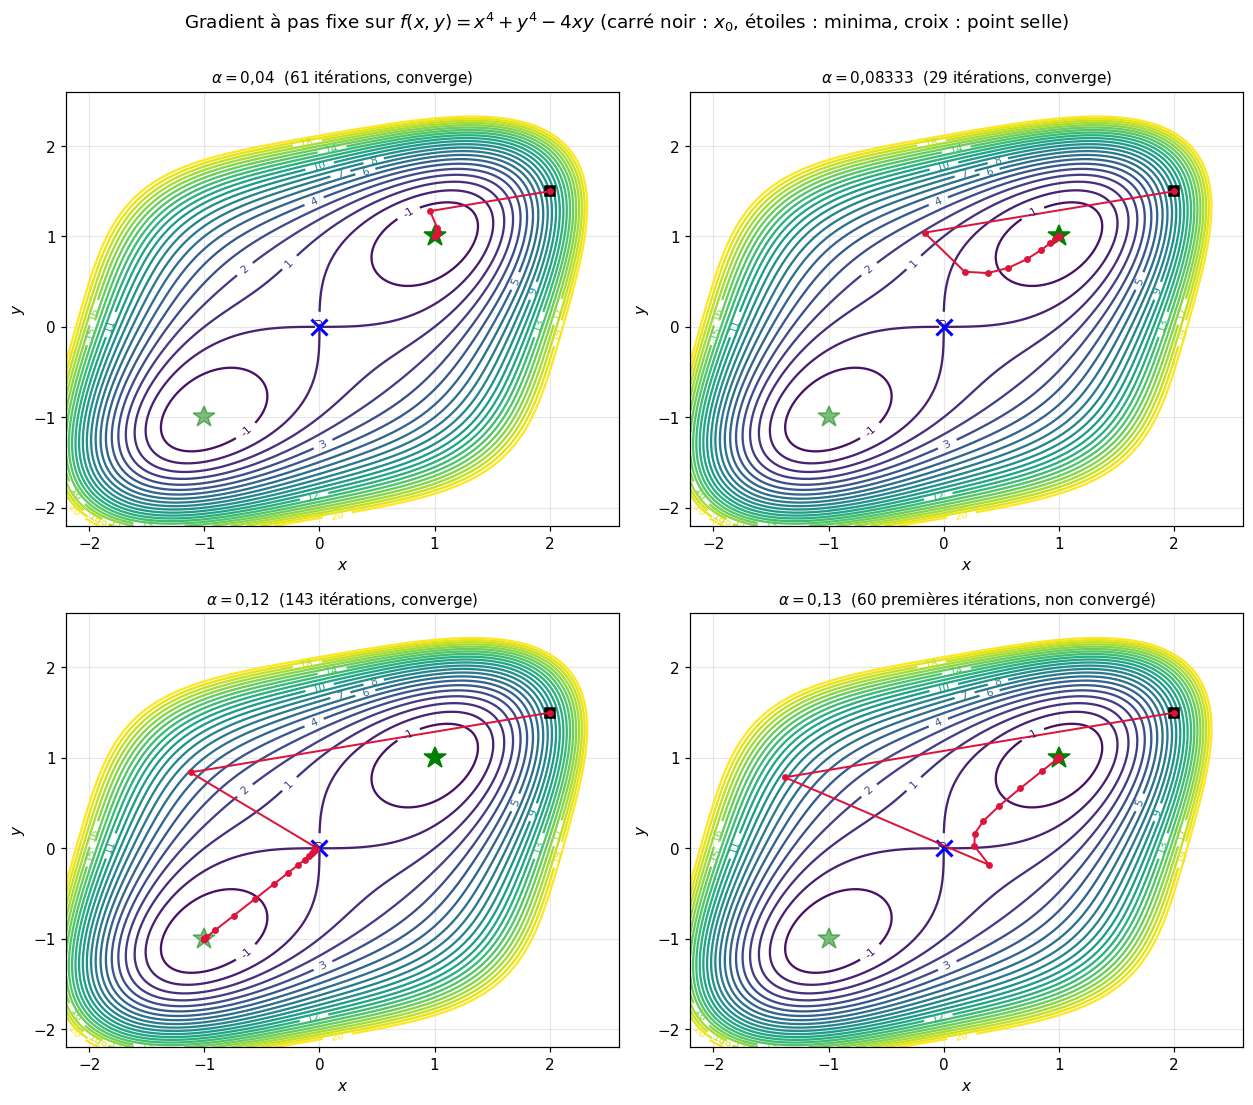

In [15]:
xs = np.linspace(-2.2, 2.6, 400); ys = np.linspace(-2.2, 2.6, 400)
X, Y = np.meshgrid(xs, ys); Z = f_num(X, Y)

def fond_contours(ax, titre):
    cs = ax.contour(X, Y, Z, levels=np.linspace(-2, 20, 23), cmap="viridis")
    ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
    ax.plot(1, 1, "g*", ms=15); ax.plot(-1, -1, "g*", ms=15, alpha=0.5); ax.plot(0, 0, "bx", ms=10, mew=2)
    ax.plot(2.0, 1.5, "ks", ms=7)
    ax.set_title(titre, fontsize=10); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")

fig, axes = plt.subplots(2, 2, figsize=(11.5, 10))
for ax, al in zip(axes.ravel(), [0.04, 1/12, 0.12, 0.13]):
    r = runs[al].iloc[:61]
    al_txt = f"{al:.4g}".replace(".", "{,}")
    fond_contours(ax, (fr"$\alpha = {al_txt}$  ({len(runs[al])-1} itérations, {statut(runs[al])})" if al != 0.13 else fr"$\alpha = {al_txt}$  (60 premières itérations, {statut(runs[al])})"))
    ax.plot(r["x"], r["y"], "o-", color="crimson", lw=1.3, ms=3.5)
plt.suptitle("Gradient à pas fixe sur $f(x,y)=x^4+y^4-4xy$ (carré noir : $x_0$, étoiles : minima, croix : point selle)", y=1.0)
plt.tight_layout(); plt.show()

### 5.7 Gradient conjugué : tableaux des itérations (FR et PR+)

Les colonnes `alpha` et `beta` donnent le pas optimal $\alpha_k$ et le coefficient $\beta_k$ utilisé pour construire $d_{k+1}$. La colonne `g_{k+1}^T d_k` doit être nulle (propriété de la recherche linéaire exacte).

In [16]:
res_fr = gradient_conjugue([2.0, 1.5], "FR")
res_fr

,k,x,y,"f(x,y)",||grad||,alpha,beta,g_{k+1}^T d_k
0,0,2,1.5,9.0625,26.57536453,0.03782045704,0.03075751333,1.154631946e-14
1,1,1.016668117,1.291987486,-1.399397564,4.660739619,0.05971741058,0.003832302498,-4.41007977e-15
2,2,1.026514608,1.009583879,-1.996168615,0.2885258519,0.08613025882,0.07677871532,1.754906938e-17
3,3,1.001733318,1.007157004,-1.999722769,0.07994754876,0.08654890676,0.005091214607,-6.908832756e-17
4,4,1.000495794,1.000083336,-1.999998648,0.005704477278,0.07772582608,0.05370740724,4.898775492e-18
5,5,1.000053384,1.000127403,-1.999999913,0.001322004544,0.09920043401,0.009348130497,2.415784798e-19
6,6,1.00001006,0.999999926,-1.999999999,0.0001278189752,0.07193195548,0.02580783524,-8.653964439e-20
7,7,1.000001061,1.00000202,-2,2.053388474e-05,0.1060021759,0.02152967684,1.907512235e-20
8,8,1.000000226,0.9999999801,-2,3.012935784e-06,0.07061372123,0.01122794111,-1.480293508e-21
9,9,1.000000017,1.000000031,-2,3.1925664e-07,0.1047745118,0.04708919601,3.406914826e-23


In [17]:
res_pr = gradient_conjugue([2.0, 1.5], "PR+")
res_pr

,k,x,y,"f(x,y)",||grad||,alpha,beta,g_{k+1}^T d_k
0,0,2,1.5,9.0625,26.57536453,0.03782045704,0.03075751333,1.154631946e-14
1,1,1.016668117,1.291987486,-1.399397564,4.660739619,0.05971741058,0.01452598405,2.098538132e-14
2,2,1.026514608,1.009583879,-1.996168615,0.2885258519,0.09221039177,0.03245131811,3.724478374e-16
3,3,1.000146537,1.002322567,-1.999968816,0.02836752053,0.0775624559,0.001369588867,1.941483273e-17
4,4,1.000010953,1.00000307,-1.999999999,0.0001193550031,0.09010786875,0.0002494529106,1.024579109e-19
5,5,1,1.000000007,-2,9.13748736e-08,0.07753869407,4.900356772e-07,-1.482424742e-23
6,6,1,1,-2,1.378995322e-13,NaN,NaN,NaN


### 5.8 Analyse de la vitesse de convergence du gradient conjugué

On calcule $e_k = \|x_k - x^\*\|_2$ et le rapport $e_{k+1}/e_k$. Pour une convergence **superlinéaire** (ou à terminaison « quasi finie »), ce rapport tend vers $0$.

In [18]:
for nom, r in [("FR", res_fr), ("PR+", res_pr)]:
    r["erreur"] = np.linalg.norm(r[["x", "y"]].values - x_star, axis=1)
    r["e_{k+1}/e_k"] = np.r_[r["erreur"].values[1:] / r["erreur"].values[:-1], np.nan]

for nom, r in [("Fletcher-Reeves", res_fr), ("Polak-Ribière+", res_pr)]:
    pf = r[["x", "y"]].values[-1]
    print(f"--- {nom} ---")
    print(f"Itérations effectuées : {len(r)-1}")
    print(f"Point final           : ({pf[0]:.12f}, {pf[1]:.12f})")
    print(f"f au point final      : {r['f(x,y)'].values[-1]:.12f}   (valeur théorique : -2)")
    print(f"||grad|| final        : {r['||grad||'].values[-1]:.2e}")
    print(f"max |g_(k+1)^T d_k|   : {np.nanmax(np.abs(r['g_{k+1}^T d_k'].values)):.2e}   (recherche linéaire exacte)")
    print("Valeurs propres du Hessien exact au point final :", np.linalg.eigvalsh(hess(pf)), "(attendu : 8 et 16)\n")

pd.DataFrame({"k": res_fr["k"], "erreur FR": res_fr["erreur"], "e_{k+1}/e_k (FR)": res_fr["e_{k+1}/e_k"]}).join(
    pd.DataFrame({"erreur PR+": res_pr["erreur"], "e_{k+1}/e_k (PR+)": res_pr["e_{k+1}/e_k"]}))

--- Fletcher-Reeves ---
Itérations effectuées : 13
Point final           : (1.000000000002, 1.000000000009)
f au point final      : -2.000000000000   (valeur théorique : -2)
||grad|| final        : 9.64e-11
max |g_(k+1)^T d_k|   : 1.15e-14   (recherche linéaire exacte)
Valeurs propres du Hessien exact au point final : [ 8. 16.] (attendu : 8 et 16)

--- Polak-Ribière+ ---
Itérations effectuées : 6
Point final           : (1.000000000000, 1.000000000000)
f au point final      : -2.000000000000   (valeur théorique : -2)
||grad|| final        : 1.38e-13
max |g_(k+1)^T d_k|   : 2.10e-14   (recherche linéaire exacte)
Valeurs propres du Hessien exact au point final : [ 8. 16.] (attendu : 8 et 16)



,k,erreur FR,e_{k+1}/e_k (FR),erreur PR+,e_{k+1}/e_k (PR+)
0,0,1.118033989,0.2615867248,1.118033989,0.2615867248
1,1,0.2924628494,0.09640038203,0.2924628494,0.09640038203
2,2,0.02819353041,0.261191292,0.02819353041,0.08254323676
3,3,0.007363904633,0.06827209145,0.002327185256,0.004887844423
4,4,0.0005027491705,0.2747601122,1.137491947e-05,0.0006588052569
5,5,0.0001381354185,0.07283116234,7.493856745e-09,1.754198963e-06
6,6,1.006056309e-05,0.2268467432,1.314571573e-14,NaN
7,7,2.282205972e-06,0.09928162318,NaN,NaN
8,8,2.265811133e-07,0.1574295227,NaN,NaN
9,9,3.567055653e-08,0.150563748,NaN,NaN


### 5.9 Courbes de convergence et chemins : gradient à pas fixe vs gradient conjugué

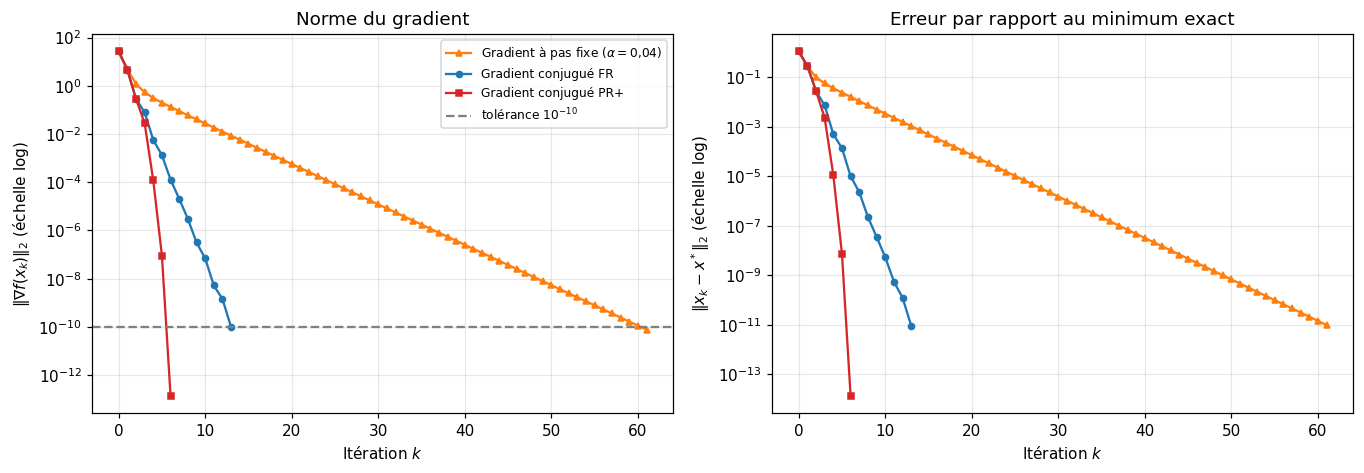

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))

for nom, r, c, mk in [(r"Gradient à pas fixe ($\alpha=0{,}04$)", res_gd, "tab:orange", "^"),
                      ("Gradient conjugué FR", res_fr, "tab:blue", "o"),
                      ("Gradient conjugué PR+", res_pr, "tab:red", "s")]:
    ax[0].semilogy(r["k"], r["||grad||"].clip(lower=1e-17), mk + "-", ms=4, color=c, label=nom)
    ax[1].semilogy(r["k"], r["erreur"].clip(lower=1e-17), mk + "-", ms=4, color=c, label=nom)
ax[0].axhline(1e-10, color="gray", ls="--", label="tolérance $10^{-10}$")
ax[0].set_title("Norme du gradient"); ax[0].set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)")
ax[1].set_title("Erreur par rapport au minimum exact"); ax[1].set_ylabel(r"$\|x_k - x^*\|_2$ (échelle log)")
for a_ in ax: a_.set_xlabel("Itération $k$")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

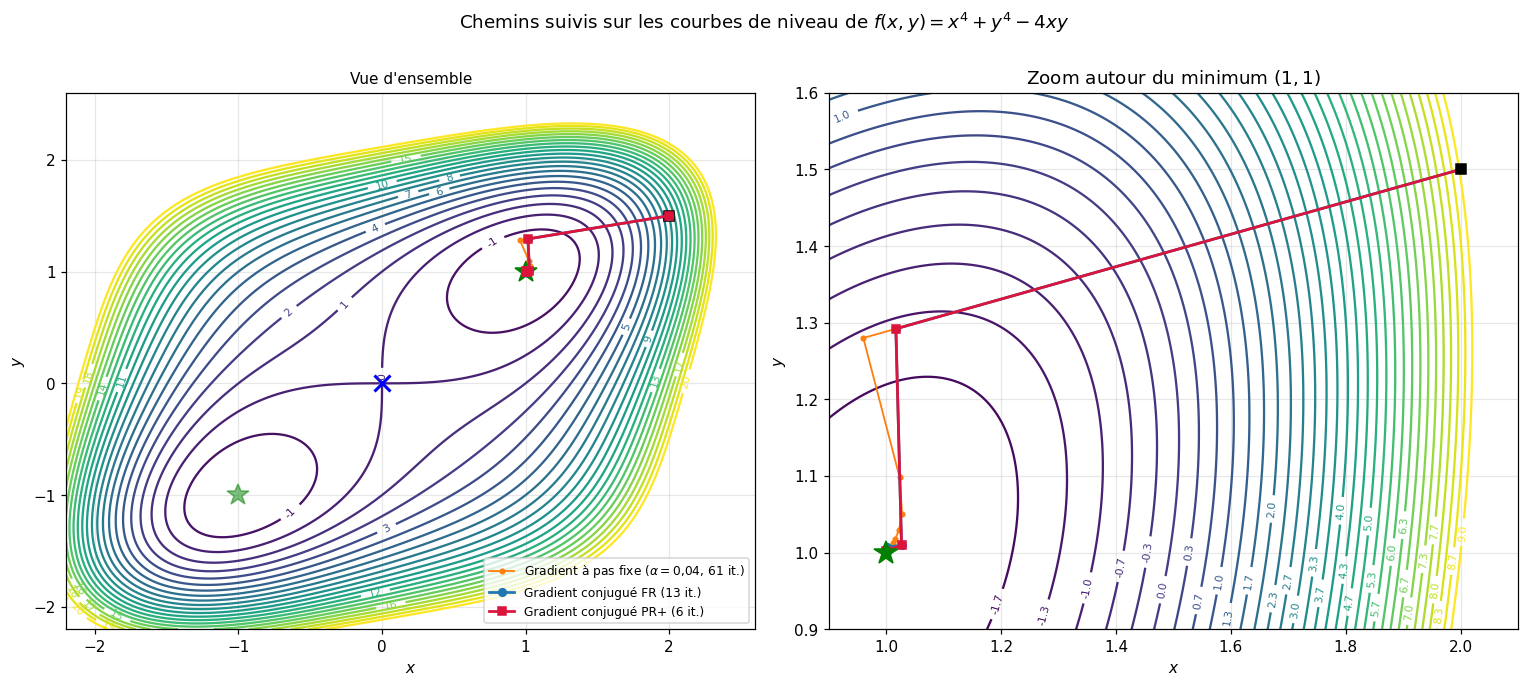

In [20]:
chemins = [(res_gd, "tab:orange", "o", 1.2, 3, r"Gradient à pas fixe ($\alpha=0{,}04$, %d it.)" % (len(res_gd)-1)),
           (res_fr, "tab:blue", "o", 1.8, 5, "Gradient conjugué FR (%d it.)" % (len(res_fr)-1)),
           (res_pr, "crimson", "s", 1.8, 5, "Gradient conjugué PR+ (%d it.)" % (len(res_pr)-1))]

fig, ax = plt.subplots(1, 2, figsize=(14, 6.2))
fond_contours(ax[0], "Vue d'ensemble")
for r, c, mk, lw, ms, lab in chemins:
    ax[0].plot(r["x"], r["y"], mk + "-", color=c, lw=lw, ms=ms, label=lab)
ax[0].legend(loc="lower right", fontsize=8)

# Zoom autour du minimum (1,1) avec des courbes de niveau plus fines
xz = np.linspace(0.9, 2.1, 300); yz = np.linspace(0.9, 1.6, 300)
Xz, Yz = np.meshgrid(xz, yz); Zz = f_num(Xz, Yz)
cs = ax[1].contour(Xz, Yz, Zz, levels=np.linspace(-2, 9, 34), cmap="viridis")
ax[1].clabel(cs, inline=True, fontsize=7, fmt="%.1f")
for r, c, mk, lw, ms, lab in chemins:
    ax[1].plot(r["x"], r["y"], mk + "-", color=c, lw=lw, ms=ms, label=lab)
ax[1].plot(1, 1, "g*", ms=16); ax[1].plot(2.0, 1.5, "ks", ms=7)
ax[1].set_xlim(0.9, 2.1); ax[1].set_ylim(0.9, 1.6)
ax[1].set_title("Zoom autour du minimum $(1,1)$"); ax[1].set_xlabel("$x$"); ax[1].set_ylabel("$y$")
plt.suptitle("Chemins suivis sur les courbes de niveau de $f(x,y)=x^4+y^4-4xy$", y=1.0)
plt.tight_layout(); plt.show()

### 5.10 Comparaison avec Newton et BFGS

On reprend les implémentations des notebooks précédents (mêmes fonctions, même point initial, même tolérance) pour comparer les quatre familles de méthodes.

In [21]:
def newton(p0, tol=1e-10, max_iter=50):
    p = np.array(p0, dtype=float); hist = []
    for k in range(max_iter + 1):
        g = grad(p)
        hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": np.linalg.norm(g)})
        if np.linalg.norm(g) < tol or k == max_iter: break
        p = p + np.linalg.solve(hess(p), -g)
    return pd.DataFrame(hist)

def armijo(p, d, g, alpha0=1.0, c1=1e-4, facteur=0.5, max_red=60):
    alpha = alpha0; f0, pente = f(p), g @ d
    for _ in range(max_red):
        if f(p + alpha * d) <= f0 + c1 * alpha * pente: return alpha
        alpha *= facteur
    return alpha

def bfgs(p0, tol=1e-10, max_iter=200):
    p = np.array(p0, dtype=float); n = len(p); H = np.eye(n); g = grad(p); hist = []
    for k in range(max_iter + 1):
        ng = np.linalg.norm(g)
        hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": ng})
        if ng < tol or k == max_iter: break
        d = -H @ g
        if g @ d >= 0: H, d = np.eye(n), -g
        alpha = armijo(p, d, g, min(1.0, 1.0 / ng) if k == 0 else 1.0)
        s = alpha * d; p_new = p + s; g_new = grad(p_new); yk = g_new - g
        if s @ yk > 1e-12 * np.linalg.norm(s) * np.linalg.norm(yk):
            rho = 1.0 / (yk @ s); V = np.eye(n) - rho * np.outer(s, yk)
            H = V @ H @ V.T + rho * np.outer(s, s)
        p, g = p_new, g_new
    return pd.DataFrame(hist)

res_gd_opt = gradient_pas_fixe([2.0, 1.5], 1/12)
res_bfgs   = bfgs([2.0, 1.5])
res_newton = newton([2.0, 1.5])

methodes = [("Gradient à pas fixe (α = 0,04)", res_gd, "non", "non", "aucune (pas constant)", "O(n)"),
            ("Gradient à pas fixe (α = 1/12)", res_gd_opt, "non", "non", "aucune (pas constant)", "O(n)"),
            ("Gradient conjugué FR", res_fr, "non", "non", "exacte (cubique)", "O(n)"),
            ("Gradient conjugué PR+", res_pr, "non", "non", "exacte (cubique)", "O(n)"),
            ("BFGS (quasi-Newton)", res_bfgs, "non", "non", "Armijo", "O(n²)"),
            ("Newton", res_newton, "oui", "oui", "aucune (pas 1)", "O(n²) + O(n³)")]
pd.DataFrame({
    "méthode": [m[0] for m in methodes],
    "itérations": [len(m[1]) - 1 for m in methodes],
    "tolérance atteinte": [bool(m[1]["||grad||"].values[-1] < 1e-10) for m in methodes],
    "f final": [m[1]["f(x,y)"].values[-1] for m in methodes],
    "||grad|| final": [f"{m[1]['||grad||'].values[-1]:.1e}" for m in methodes],
    "Hessien exact requis": [m[2] for m in methodes],
    "système linéaire": [m[3] for m in methodes],
    "pas": [m[4] for m in methodes],
    "coût/itération (hors f, ∇f)": [m[5] for m in methodes]})

,méthode,itérations,tolérance atteinte,f final,||grad|| final,Hessien exact requis,système linéaire,pas,"coût/itération (hors f, ∇f)"
0,"Gradient à pas fixe (α = 0,04)",61,True,-2,7.8e-11,non,non,aucune (pas constant),O(n)
1,Gradient à pas fixe (α = 1/12),29,True,-2,3.7e-11,non,non,aucune (pas constant),O(n)
2,Gradient conjugué FR,13,True,-2,9.6e-11,non,non,exacte (cubique),O(n)
3,Gradient conjugué PR+,6,True,-2,1.4e-13,non,non,exacte (cubique),O(n)
4,BFGS (quasi-Newton),13,True,-2,1.2e-12,non,non,Armijo,O(n²)
5,Newton,6,True,-2,2.0e-13,oui,oui,aucune (pas 1),O(n²) + O(n³)


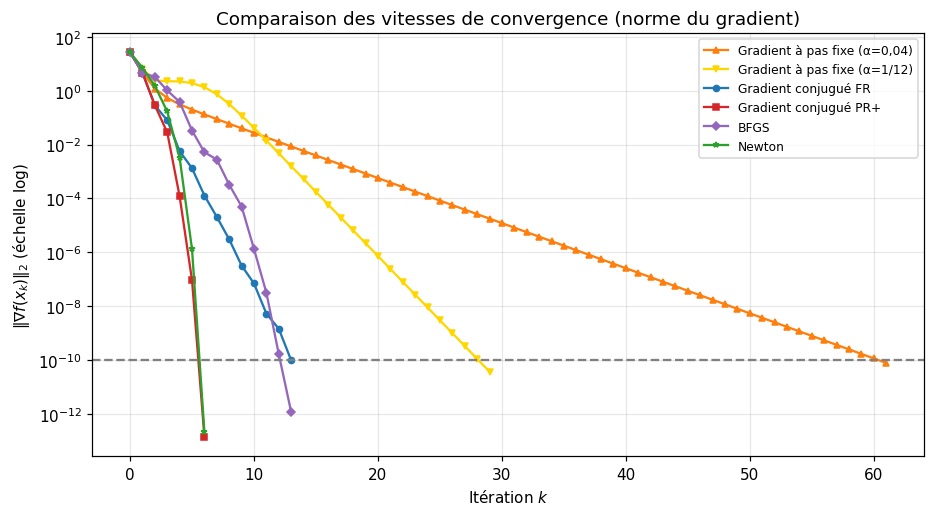

In [22]:
fig, ax = plt.subplots(figsize=(8.6, 4.8))
for nom, r, c, mk in [("Gradient à pas fixe (α=0,04)", res_gd, "tab:orange", "^"),
                      ("Gradient à pas fixe (α=1/12)", res_gd_opt, "gold", "v"),
                      ("Gradient conjugué FR", res_fr, "tab:blue", "o"),
                      ("Gradient conjugué PR+", res_pr, "tab:red", "s"),
                      ("BFGS", res_bfgs, "tab:purple", "D"),
                      ("Newton", res_newton, "tab:green", "*")]:
    ax.semilogy(r["k"], r["||grad||"].clip(lower=1e-17), mk + "-", ms=4, color=c, label=nom)
ax.axhline(1e-10, color="gray", ls="--")
ax.set_title("Comparaison des vitesses de convergence (norme du gradient)")
ax.set_xlabel("Itération $k$"); ax.set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Partie 6 — Interprétation et conclusion

### 6.1 Bilan de la convergence

In [23]:
for nom, r in [("Gradient à pas fixe (α = 0,04)", res_gd), ("Gradient à pas fixe (α = 1/12)", res_gd_opt),
               ("Gradient conjugué FR", res_fr), ("Gradient conjugué PR+", res_pr),
               ("BFGS", res_bfgs), ("Newton", res_newton)]:
    pf = r[["x", "y"]].values[-1]
    print(f"{nom:34s}: {len(r)-1:3d} itérations,  x* = ({pf[0]:.10f}, {pf[1]:.10f}),  f(x*) = {r['f(x,y)'].values[-1]:.10f}")

Gradient à pas fixe (α = 0,04)    :  61 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient à pas fixe (α = 1/12)    :  29 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient conjugué FR              :  13 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient conjugué PR+             :   6 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
BFGS                              :  13 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Newton                            :   6 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000


Les résultats numériques sont **cohérents avec l'analyse mathématique** des Parties 1 et 3 :

- **Les deux méthodes convergent vers $(1,1)$**, l'un des deux minima globaux, avec $f = -2$ ; en ce point le gradient est nul (à la tolérance près) et le Hessien est défini positif (valeurs propres $8$ et $16$) : les conditions d'optimalité sont vérifiées.
- **Gradient à pas fixe** : la convergence est **linéaire**. Le rapport $e_{k+1}/e_k$ se stabilise exactement sur le taux théorique $\rho(\alpha) = \max(|1-8\alpha|, |1-16\alpha|)$ : $0{,}68$ pour $\alpha = 0{,}04$ (61 itérations, pour environ 68 prévues) et $1/3$ pour $\alpha = 1/12$ (29 itérations). Les valeurs de $f$ décroissent à chaque itération (à la précision machine près), conformément au lemme de descente ($\alpha < 2/L$).
- **Gradient conjugué** : les directions successives corrigent le zigzag du gradient. PR+ converge en **6 itérations** et FR en **13**, soit environ 5 à 10 fois moins d'itérations que le gradient à pas fixe avec $\alpha = 0{,}04$ (et 2 à 5 fois moins qu'avec le pas optimal local). Pour **PR+**, le rapport $e_{k+1}/e_k$ tend vers $0$ ($0{,}26$ ; $0{,}10$ ; $0{,}08$ ; $5\cdot10^{-3}$ ; $7\cdot10^{-4}$ ; $2\cdot10^{-6}$) : la convergence est **superlinéaire**. Pour **FR**, il oscille entre $0{,}07$ et $0{,}27$ sans tendre vers $0$ sur les 13 itérations observées (soit un gain moyen d'environ $0{,}14$ par itération) : c'est une convergence linéaire rapide, moins bonne que celle de PR+, car FR « oublie » moins bien les anciennes directions lorsque $f$ n'est pas quadratique. La colonne $g_{k+1}^\top d_k$ est nulle à la précision machine : la recherche linéaire exacte fonctionne comme prévu.
- **Modèle quadratique** : sur $q(z)=\tfrac12 z^\top H_f(1,1) z$, le gradient conjugué termine en exactement $n = 2$ itérations, avec des directions $A$-conjuguées ($d_0^\top A d_1 = 0$ à la précision machine). Pour $f$ (quartique), la méthode n'est exacte qu'asymptotiquement, car $f$ n'est quadratique qu'au voisinage de $x^\*$.
- **Comparaison** : PR+ (6 itérations, gradient seul) rivalise avec Newton (6 itérations, qui exige Hessien et système linéaire) et fait mieux que BFGS (13 itérations) sur cet exemple. Le coût d'une itération du gradient conjugué reste en $O(n)$ en mémoire et en calcul, sans matrice à stocker.

### 6.2 Limites des méthodes

**(a) Le dilemme du pas fixe.** Le tableau du §5.4 et la figure associée résument le compromis :

- un pas **trop petit** garantit la stabilité mais ralentit la convergence : le nombre d'itérations varie comme $1/\alpha$ (près de 600 itérations pour $\alpha = 0{,}005$, contre 29 pour $\alpha = 1/12$) ;
- le pas **optimal local** $\alpha = 1/12$ est **supérieur** à la borne $2/L \approx 0{,}04$ qui garantit la décroissance depuis $x_0$ : il fonctionne ici, mais sans garantie théorique, et on ne peut pas le connaître sans connaître le Hessien ;
- pour $\alpha = 0{,}12$, la courbe de $f$ reste décroissante, mais le premier pas, très grand, projette l'itéré dans le bassin d'attraction de l'**autre minimum** $(-1,-1)$ ; le taux local $\rho = 0{,}92$ rend la convergence lente ;
- à $\alpha = 2/\lambda_{\max} = 0{,}125$, le taux local vaut $1$ : l'algorithme n'atteint plus la tolérance ;
- à $\alpha = 0{,}13$ ($\rho = 1{,}08 > 1$), les itérés restent piégés dans une oscillation (cycle) de grande amplitude autour de $(1,1)$ et n'atteignent jamais la tolérance ($\|\nabla f\| \approx 3$ après 20 000 itérations) ; à $\alpha = 0{,}15$, l'algorithme **diverge** (explosion en 4 itérations). La fonction étant quartique, la courbure, et donc la limite de stabilité, varient fortement d'un endroit à l'autre.

**(b) Dépendance au point initial et comportement face au point selle.** Les méthodes de descente (à pas $\alpha<2/L$ ou avec recherche linéaire) ne peuvent pas converger vers un point selle, sauf situation exceptionnelle. Testons-le sur les points de départ déjà utilisés pour Newton et BFGS, avec le gradient conjugué FR, FR avec **redémarrage toutes les 2 itérations** et PR+ (une colonne indique les cas où la tolérance n'est pas atteinte en 500 itérations).

In [24]:
def resume(r, tol=1e-10):
    pf = r[["x", "y"]].values[-1]
    ok = r["||grad||"].values[-1] < tol
    return f"{len(r)-1} it. -> ({pf[0]:.3f}; {pf[1]:.3f})" + ("" if ok else "  [tolérance non atteinte]")

departs = [(2.0, 1.5), (-1.5, -2.0), (0.3, 0.2), (-0.3, 0.1), (1.0, -0.5), (1.0, -1.0)]
lignes = []
for p_ in departs:
    lignes.append({"x0": p_,
                   "Gradient pas fixe (α=0,04)": resume(gradient_pas_fixe(p_, 0.04)),
                   "GC FR": resume(gradient_conjugue(p_, "FR", max_iter=500)),
                   "GC FR + redémarrage (2)": resume(gradient_conjugue(p_, "FR", max_iter=500, redemarrage=2)),
                   "GC PR+": resume(gradient_conjugue(p_, "PR+", max_iter=500))})
pd.DataFrame(lignes)

,x0,"Gradient pas fixe (α=0,04)",GC FR,GC FR + redémarrage (2),GC PR+
0,"(2.0, 1.5)",61 it. -> (1.000; 1.000),13 it. -> (1.000; 1.000),8 it. -> (1.000; 1.000),6 it. -> (1.000; 1.000)
1,"(-1.5, -2.0)",61 it. -> (-1.000; -1.000),13 it. -> (-1.000; -1.000),8 it. -> (-1.000; -1.000),6 it. -> (-1.000; -1.000)
2,"(0.3, 0.2)",74 it. -> (1.000; 1.000),134 it. -> (1.000; 1.000),8 it. -> (1.000; 1.000),7 it. -> (1.000; 1.000)
3,"(-0.3, 0.1)",81 it. -> (-1.000; -1.000),500 it. -> (1.000; 1.000) [tolérance non atte...,9 it. -> (-1.000; -1.000),9 it. -> (-1.000; -1.000)
4,"(1.0, -0.5)",78 it. -> (1.000; 1.000),145 it. -> (-1.000; -1.000),8 it. -> (1.000; 1.000),9 it. -> (1.000; 1.000)
5,"(1.0, -1.0)",140 it. -> (0.000; -0.000),1 it. -> (0.000; 0.000),1 it. -> (0.000; 0.000),1 it. -> (0.000; 0.000)


Observations :

- Pour les départs proches du point selle, $(0{,}3;\,0{,}2)$ et $(-0{,}3;\,0{,}1)$, **toutes les méthodes quittent la zone du point selle** et se dirigent vers un minimum ($f=-2$) : contrairement à Newton, ce sont des méthodes de descente.
- **Cas particulier $(1;\,-1)$.** Tous les algorithmes convergent vers $(0,0)$, pour la même raison de symétrie que pour BFGS : sur la droite $y=-x$, le gradient reste colinéaire à $(1,-1)$, donc tous les itérés restent sur cette droite, où la restriction $f(t,-t) = 2t^4 + 4t^2$ est minimale en $t=0$. Pour le gradient conjugué avec recherche linéaire exacte, **la première itération suffit** à atteindre ce minimum sur la droite, et le gradient s'y annule. C'est un cas exceptionnel : le moindre écart hors de la droite (par exemple $(1;\,-0{,}5)$) l'évite.
- Le **gradient conjugué FR sans redémarrage** est nettement moins régulier que PR+ : il lui faut plus de 100 itérations pour certains départs, et il n'atteint même pas la tolérance en 500 itérations pour $(-0{,}3;\,0{,}1)$, alors que FR avec redémarrage (ou PR+) en demande moins de 10. Voir (d).

**(c) Conditionnement.** Ici $\kappa = 16/8 = 2$ : le problème est **très bien conditionné**, ce qui est favorable au gradient à pas fixe. Le gradient conjugué garde malgré tout un net avantage. Sur une quadratique mal conditionnée, l'écart devient spectaculaire : le taux du gradient à pas fixe est $\frac{\kappa-1}{\kappa+1}$, celui du gradient conjugué est borné par $\frac{\sqrt\kappa-1}{\sqrt\kappa+1}$, et la terminaison en $n$ itérations reste valable. Illustration avec $q(z) = \tfrac12(z_1^2 + 100\,z_2^2)$, soit $\kappa = 100$ :

In [25]:
kappa = 100.0
A_mal = np.diag([1.0, kappa]); b0 = np.zeros(2); z_init = np.array([1.0, 1.0])

def gd_quadratique(A, z0, alpha, tol=1e-10, max_iter=200000):
    z = np.array(z0, dtype=float)
    for k in range(max_iter + 1):
        g = A @ z
        if np.linalg.norm(g) < tol:
            return k
        z = z - alpha * g
    return max_iter

mu_q, L_q = 1.0, kappa
pd.DataFrame([
    {"méthode": "Gradient à pas fixe, α = 1/L",
     "itérations": gd_quadratique(A_mal, z_init, 1/L_q), "taux théorique": 1 - mu_q/L_q},
    {"méthode": "Gradient à pas fixe, α = 2/(μ+L)",
     "itérations": gd_quadratique(A_mal, z_init, 2/(mu_q+L_q)), "taux théorique": (L_q-mu_q)/(L_q+mu_q)},
    {"méthode": "Gradient conjugué",
     "itérations": len(gc_quadratique(A_mal, b0, z_init, tol=1e-10)) - 1,
     "taux théorique": "terminaison en n = 2 itérations (borne : %.3f)" % ((np.sqrt(kappa)-1)/(np.sqrt(kappa)+1))}])

,méthode,itérations,taux théorique
0,"Gradient à pas fixe, α = 1/L",2292,0.99
1,"Gradient à pas fixe, α = 2/(μ+L)",1382,0.9801980198
2,Gradient conjugué,2,terminaison en n = 2 itérations (borne : 0.818)


Avec $\kappa=100$, le gradient à pas fixe a besoin de **plus d'un millier** d'itérations (1 382 avec le pas optimal, 2 292 avec $\alpha=1/L$), alors que le gradient conjugué termine en 2. C'est la raison pour laquelle le gradient conjugué (souvent préconditionné) est la méthode de référence pour les grands systèmes linéaires symétriques définis positifs et les problèmes mal conditionnés.

**(d) Limites propres au gradient conjugué non linéaire.** Pour une fonction non quadratique, les directions ne sont plus exactement conjuguées. Fletcher–Reeves peut alors avoir une convergence **extrêmement lente** (quasi-stagnation) : si un pas est très court loin du minimum, $\|g_{k+1}\| \approx \|g_k\|$ donc $\beta_k \approx 1$, et la nouvelle direction reste presque identique à la précédente (« coincement »). Polak–Ribière+ se corrige seul, car $\beta_k^{PR}$ devient petit dans ce cas. Un **redémarrage** périodique, qui remplace $d_k$ par $-g_k$ toutes les $n$ itérations, produit le même effet. Illustration depuis $(-0{,}3;\ 0{,}1)$ :

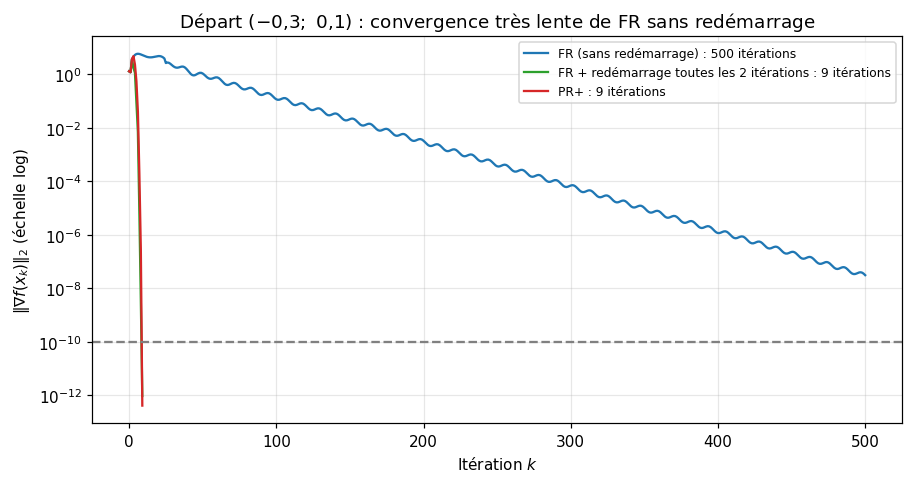

In [26]:
p_test = (-0.3, 0.1)
essais = [("FR (sans redémarrage)", gradient_conjugue(p_test, "FR", max_iter=500), "tab:blue"),
          ("FR + redémarrage toutes les 2 itérations", gradient_conjugue(p_test, "FR", max_iter=500, redemarrage=2), "tab:green"),
          ("PR+", gradient_conjugue(p_test, "PR+", max_iter=500), "tab:red")]
fig, ax = plt.subplots(figsize=(8.4, 4.5))
for nom, r, c in essais:
    ax.semilogy(r["k"], r["||grad||"].clip(lower=1e-17), "-", color=c, label=f"{nom} : {len(r)-1} itérations")
ax.axhline(1e-10, color="gray", ls="--")
ax.set_title(r"Départ $(-0{,}3;\ 0{,}1)$ : convergence très lente de FR sans redémarrage")
ax.set_xlabel("Itération $k$"); ax.set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Enfin, la recherche linéaire exacte n'est ici possible à très bas coût que parce que $f$ est polynomiale (cubique à résoudre). Pour une fonction générale, chaque itération exige une recherche linéaire inexacte vérifiant les **conditions de Wolfe**, qui coûte plusieurs évaluations de $f$ et de $\nabla f$ ; Fletcher–Reeves requiert alors les conditions de Wolfe *fortes* pour garantir la descente.

### 6.3 Remèdes classiques

- **Pas adaptatif** pour la descente de gradient : recherche linéaire d'Armijo (backtracking), pas de **Barzilai–Borwein**, qui estime la courbure locale à partir de $s_k$ et $y_k$ ;
- **Accélération** de la descente de gradient : méthode de la boule lourde (*momentum*), accélération de Nesterov, dont le taux dépend de $\sqrt\kappa$ comme pour le gradient conjugué (c'est la base des optimiseurs de Deep Learning) ;
- **Gradient conjugué** : coefficient PR+ (ou Hestenes–Stiefel+), **redémarrage** périodique, recherche linéaire de **Wolfe**, et **préconditionnement** pour réduire $\kappa$ ;
- **Quasi-Newton** (BFGS, L-BFGS) lorsque la mémoire permet de stocker quelques paires $(s_k, y_k)$ : convergence superlinéaire sans Hessien.

### 6.4 Conclusion

Appliquées à $f(x,y)=x^4+y^4-4xy$ depuis $x_0=(2;\,1{,}5)$, les deux méthodes convergent vers le minimum global $(1,1)$ avec $f=-2$, en accord avec la résolution analytique.

- Le **gradient à pas fixe** est la méthode la plus simple (une ligne de code, un gradient par itération, aucune recherche linéaire), mais sa **convergence est seulement linéaire** : 61 itérations pour $\alpha=0{,}04$ et 29 pour le pas optimal local $\alpha=1/12$. Son efficacité dépend fortement du choix de $\alpha$, qui doit rester inférieur à $2/L$ où $L$ est la plus grande courbure rencontrée ; trop grand, il oscille ou diverge, trop petit, il est lent.
- Le **gradient conjugué** garde le même coût par itération en $O(n)$, sans matrice ni système linéaire, mais exploite la mémoire de la direction précédente : il converge en 6 itérations (PR+) ou 13 (FR), termine en $n$ itérations sur une quadratique et conserve ses performances quand $\kappa$ augmente. Il demande en échange une recherche linéaire soignée et, pour FR, un redémarrage.

Ces deux méthodes complètent le panorama obtenu avec Newton (2ᵉ ordre, convergence quadratique, coût élevé) et BFGS (quasi-Newton, convergence superlinéaire) : en grande dimension, où le Hessien est hors de portée, ce sont leurs descendants (gradient conjugué préconditionné, L-BFGS, gradient stochastique avec momentum) qui sont utilisés pour entraîner les modèles de Machine Learning.